# Plot with channel contributions

In [ ]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.config import PATH_TO_POSYDON
from posydon.popsyn.rate_calculation import get_shell_comoving_volume
from posydon.popsyn.synthetic_population import Rates
from scipy.stats import gaussian_kde
from pathlib import Path
plt.style.use(
    str(Path(PATH_TO_POSYDON) / "posydon" / "visualization" / "posydon.mplstyle")
)


import numpy as np
data = {
    #    SMT1, SMT2, NoMT1, NoMT2, Unstable1, Unstable2
    0.1:  [47, 16, 20, 7, 5, 4],
    0.2:  [49, 19, 17, 7, 3, 4],
    0.45: [45, 19, 16, 10, 2, 5],
    1.0:  [41, 14, 27, 11, 2, 4], # updated
}

In [ ]:
labels = ["Stable (S1)", "Stable (S2)", "No MT (S1)", "No MT (S2)","Unstable (S1)", "Unstable (S2)", ]
metallicities = np.array(list(data.keys()))
values = np.array(list(data.values()))  # shape (4, 6)

In [17]:
from cmap import Colormap
colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[2],
           "Unstable (S2)": colours[3],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }

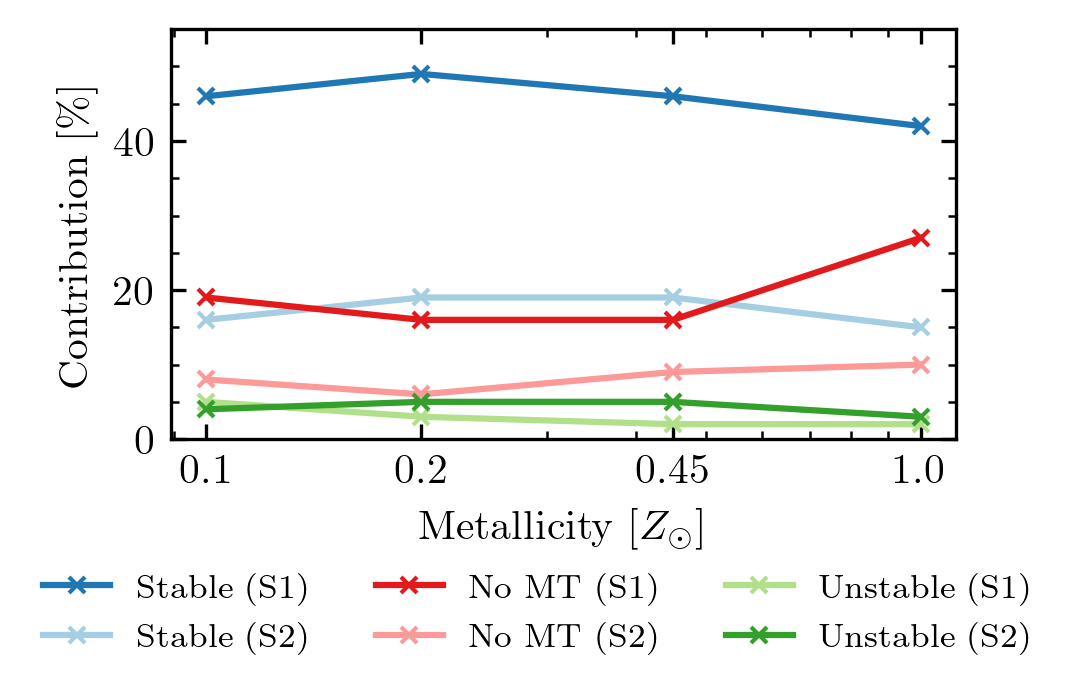

In [31]:

# Line + marker plot (non-stacked)
fig3, ax3 = plt.subplots(1, 1, figsize=(3.38, 2.535*0.7))

for i, label in enumerate(labels):
    ax3.plot(metallicities, values[:, i], marker='x', label=label, color=colours[label])

ax3.set_xlabel('Metallicity [$Z_\\odot$]')
ax3.set_ylabel('Contribution [\%]')
ax3.legend(fontsize=6)

ax3.legend(loc='upper left', bbox_to_anchor=(-0.2, -0.25), ncol=3)
ax3.set_xscale('log')
ax3.set_ylim(0, 55)
ax3.set_xticks([0.1, 0.2, 0.45, 1.0])
ax3.set_xticklabels([0.1, 0.2, 0.45, 1.0])

figure_folder = '/Users/max/Documents/projects/WR_population/figure_scripts/figures/'

plt.savefig(figure_folder + '/pdf/relative_contributions.pdf', bbox_inches='tight')
plt.savefig(figure_folder + '/png/relative_contributions.png', bbox_inches='tight', dpi=300)
